In [1]:
import os
import warnings
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
from scipy import stats
from scipy.stats import chi2_contingency, norm
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, matthews_corrcoef
)

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
N_BOOTSTRAP = 1000

BASE_DIR = Path('../outputs/hybrid')
FIG_DIR  = Path('../figures')
TAB_DIR  = Path('../tables')
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)


plt.rcParams.update({
    'figure.dpi': 150,
    'font.size': 11,
    'font.family': 'serif',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'legend.fontsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
})


COLORS = {
    'Hybrid':     '#001f5b',   
    'XGBoost':    '#4682b4',   
    'VQC (LDA)':  '#cd5c5c',   
}

print('Configuration complete.')
print(f'N_BOOTSTRAP = {N_BOOTSTRAP}')
print(f'BASE_DIR    = {BASE_DIR.resolve()}')
print(f'FIG_DIR     = {FIG_DIR.resolve()}')
print(f'TAB_DIR     = {TAB_DIR.resolve()}')

Configuration complete.
N_BOOTSTRAP = 1000
BASE_DIR    = C:\Users\shanm\AppData\Local\Temp\pj\rt\outputs\hybrid
FIG_DIR     = C:\Users\shanm\AppData\Local\Temp\pj\rt\figures
TAB_DIR     = C:\Users\shanm\AppData\Local\Temp\pj\rt\tables


In [2]:

df = pd.read_csv("../outputs/hybrid/final_hybrid_predictions_train_calibrated.csv")
print(f'Loaded: {df.shape[0]} rows x {df.shape[1]} columns')
print('\nColumn names:', df.columns.tolist())
print('\nFirst 8 rows (key columns):')
print(df[['y_true', 'xgb_pred', 'vqc_pred', 'hybrid_pred']].head(8).to_string(index=True))


y_true        = df['y_true'].values.astype(int)
hybrid_pred   = df['hybrid_pred'].values.astype(int)
xgb_pred      = df['xgb_pred'].values.astype(int)
vqc_pred      = df['vqc_pred'].values.astype(int)
hybrid_score  = df['hybrid_score'].values.astype(float)
xgb_score = df['calibrated_xgb_proba'].values.astype(float)  # XGB quantile calibrated
vqc_score = df['vqc_proba'].values.astype(float)
xgb_raw       = df['xgb_proba'].values.astype(float)
vqc_raw       = df['vqc_proba'].values.astype(float)

n_total    = len(y_true)
n_diabetic = int(y_true.sum())
n_nondiab  = int((y_true == 0).sum())

print(f'\nClass distribution:')
print(f'  Diabetic     (y=1): {n_diabetic}')
print(f'  Non-diabetic (y=0): {n_nondiab}')
print(f'  Total             : {n_total}')
print(f'\nProbability ranges:')
print(f'  XGBoost raw proba : [{xgb_raw.min():.4f}, {xgb_raw.max():.4f}]')
print(f'  VQC raw proba     : [{vqc_raw.min():.4f}, {vqc_raw.max():.4f}]')
print(f'  Hybrid score      : [{hybrid_score.min():.4f}, {hybrid_score.max():.4f}]')

Loaded: 154 rows x 10 columns

Column names: ['sample_id', 'y_true', 'xgb_proba', 'xgb_pred', 'vqc_proba', 'vqc_pred', 'calibrated_xgb_proba', 'calibrated_vqc_proba', 'hybrid_score', 'hybrid_pred']

First 8 rows (key columns):
   y_true  xgb_pred  vqc_pred  hybrid_pred
0       0         1         1            1
1       0         0         0            0
2       0         1         0            1
3       0         0         0            0
4       0         1         1            1
5       1         1         1            1
6       1         0         0            0
7       0         0         1            0

Class distribution:
  Diabetic     (y=1): 54
  Non-diabetic (y=0): 100
  Total             : 154

Probability ranges:
  XGBoost raw proba : [0.0023, 0.9625]
  VQC raw proba     : [0.2041, 0.7980]
  Hybrid score      : [0.1021, 0.8910]


In [3]:
def mcnemar_test(y_true, pred_a, pred_b, label_a='Model A', label_b='Model B'):
    """
    McNemar's test with Yates' continuity correction.

    Contingency table notation:
        b = A wrong, B correct  (n01)
        c = A correct, B wrong  (n10)
    Test statistic: chi2 = (|b - c| - 1)^2 / (b + c)
    """
    correct_a = (pred_a == y_true).astype(int)
    correct_b = (pred_b == y_true).astype(int)

    n00 = int(np.sum((correct_a == 0) & (correct_b == 0)))  
    n01 = int(np.sum((correct_a == 0) & (correct_b == 1)))  
    n10 = int(np.sum((correct_a == 1) & (correct_b == 0)))  
    n11 = int(np.sum((correct_a == 1) & (correct_b == 1)))  

    b, c = n01, n10  

    if b + c == 0:
        chi2_stat, p_value = 0.0, 1.0
    else:
        chi2_stat = (abs(b - c) - 1) ** 2 / (b + c)
        p_value   = 1.0 - stats.chi2.cdf(chi2_stat, df=1)

    return {
        'label_a': label_a,
        'label_b': label_b,
        'n00': n00, 'n01': n01, 'n10': n10, 'n11': n11,
        'b_discordant': b,
        'c_discordant': c,
        'total_discordant': b + c,
        'chi2_stat':          round(chi2_stat, 4),
        'p_value':            round(p_value, 4),
        'significant_at_0.05': p_value < 0.05,
        'significant_at_0.10': p_value < 0.10,
    }



mcnemar_results = []
tests_mcnemar = [
    (hybrid_pred, xgb_pred, 'Hybrid', 'XGBoost'),
    (hybrid_pred, vqc_pred, 'Hybrid', 'VQC (LDA)'),
]

for pa, pb, la, lb in tests_mcnemar:
    result = mcnemar_test(y_true, pa, pb, la, lb)
    mcnemar_results.append(result)

    print(f"McNemar's Test: {la} vs {lb}")
    print(f'  Contingency table:')
    print(f'    Both correct      (n11): {result["n11"]}')
    print(f'    Both wrong        (n00): {result["n00"]}')
    print(f'    A correct/B wrong (n10): {result["c_discordant"]}  <- c')
    print(f'    A wrong/B correct (n01): {result["b_discordant"]}  <- b')
    print(f'  Total discordant pairs  : {result["total_discordant"]}')
    print(f'  Chi-squared statistic   : {result["chi2_stat"]}')
    print(f'  p-value                 : {result["p_value"]}')
    print(f'  Significant at alpha=0.05: {result["significant_at_0.05"]}')
    print(f'  Significant at alpha=0.10: {result["significant_at_0.10"]}')
    print()


df_mcnemar = pd.DataFrame(mcnemar_results)
display_cols = ['label_a', 'label_b', 'b_discordant', 'c_discordant',
                'chi2_stat', 'p_value', 'significant_at_0.05', 'significant_at_0.10']
print('McNemar Summary Table:')
print(df_mcnemar[display_cols].to_string(index=False))

# Save
df_mcnemar.to_csv(TAB_DIR / 'mcnemar_test_results.csv', index=False)
print('\nSaved: mcnemar_test_results.csv')

McNemar's Test: Hybrid vs XGBoost
  Contingency table:
    Both correct      (n11): 125
    Both wrong        (n00): 25
    A correct/B wrong (n10): 4  <- c
    A wrong/B correct (n01): 0  <- b
  Total discordant pairs  : 4
  Chi-squared statistic   : 2.25
  p-value                 : 0.1336
  Significant at alpha=0.05: False
  Significant at alpha=0.10: False

McNemar's Test: Hybrid vs VQC (LDA)
  Contingency table:
    Both correct      (n11): 105
    Both wrong        (n00): 17
    A correct/B wrong (n10): 24  <- c
    A wrong/B correct (n01): 8  <- b
  Total discordant pairs  : 32
  Chi-squared statistic   : 7.0312
  p-value                 : 0.008
  Significant at alpha=0.05: True
  Significant at alpha=0.10: True

McNemar Summary Table:
label_a   label_b  b_discordant  c_discordant  chi2_stat  p_value  significant_at_0.05  significant_at_0.10
 Hybrid   XGBoost             0             4     2.2500   0.1336                False                False
 Hybrid VQC (LDA)             8 

In [4]:
def delong_roc_variance(ground_truth, predictions):
    """Compute AUC and its variance using DeLong's structural component method."""
    gt   = ground_truth.astype(int)
    pred = predictions.astype(float)
    n1   = int(gt.sum())
    n0   = int((gt == 0).sum())

    pos_scores = pred[gt == 1]
    neg_scores = pred[gt == 0]

  
    V10 = np.array([
        np.mean(s > neg_scores) + 0.5 * np.mean(s == neg_scores)
        for s in pos_scores
    ])
   
    V01 = np.array([
        np.mean(pos_scores > s) + 0.5 * np.mean(pos_scores == s)
        for s in neg_scores
    ])

    auc     = float(np.mean(V10))
    var_auc = float(np.var(V10, ddof=1) / n1 + np.var(V01, ddof=1) / n0)
    return auc, var_auc, V10, V01


def delong_test(y_true, score_a, score_b, label_a='A', label_b='B'):
    """DeLong's test for two correlated AUC values."""
    auc_a, var_a, V10_a, V01_a = delong_roc_variance(y_true, score_a)
    auc_b, var_b, V10_b, V01_b = delong_roc_variance(y_true, score_b)

    n1 = int(y_true.sum())
    n0 = int((y_true == 0).sum())

    # Covariance between AUC_a and AUC_b
    cov_10 = float(np.cov(V10_a, V10_b, ddof=1)[0, 1]) / n1
    cov_01 = float(np.cov(V01_a, V01_b, ddof=1)[0, 1]) / n0
    cov    = cov_10 + cov_01

    diff   = auc_a - auc_b
    se     = float(np.sqrt(max(var_a + var_b - 2.0 * cov, 1e-15)))
    z_stat = diff / se
    p_val  = float(2.0 * (1.0 - norm.cdf(abs(z_stat))))

    ci_lo  = diff - 1.96 * se
    ci_hi  = diff + 1.96 * se

    return {
        'label_a':          label_a,
        'label_b':          label_b,
        'auc_a':            round(auc_a * 100, 2),
        'auc_b':            round(auc_b * 100, 2),
        'diff_pct':         round(diff * 100, 2),
        'se_diff':          round(se, 6),
        'z_stat':           round(z_stat, 4),
        'p_value':          round(p_val, 4),
        'significant_at_0.05': p_val < 0.05,
        'ci_lower_95':      round(ci_lo * 100, 2),
        'ci_upper_95':      round(ci_hi * 100, 2),
    }



delong_results = []
tests_delong = [
    (hybrid_score, xgb_raw, 'Hybrid', 'XGBoost'),
    (hybrid_score, vqc_raw, 'Hybrid', 'VQC (LDA)'),
]

for sa, sb, la, lb in tests_delong:
    result = delong_test(y_true, sa, sb, la, lb)
    delong_results.append(result)

    print(f"DeLong Test: {la} (AUC = {result['auc_a']}%) vs {lb} (AUC = {result['auc_b']}%)")
    print(f'  AUC difference   : {result["diff_pct"]:+.2f}%')
    print(f'  Standard error   : {result["se_diff"]:.6f}')
    print(f'  95% CI on diff   : [{result["ci_lower_95"]}%, {result["ci_upper_95"]}%]')
    print(f'  Z-statistic      : {result["z_stat"]}')
    print(f'  p-value          : {result["p_value"]}')
    print(f'  Significant (0.05): {result["significant_at_0.05"]}')
    print()

df_delong = pd.DataFrame(delong_results)
print('DeLong Summary Table:')
display_cols_dl = ['label_a', 'label_b', 'auc_a', 'auc_b', 'diff_pct',
                   'ci_lower_95', 'ci_upper_95', 'z_stat', 'p_value', 'significant_at_0.05']
print(df_delong[display_cols_dl].to_string(index=False))

df_delong.to_csv(TAB_DIR / 'delong_auc_comparison.csv', index=False)
print('\nSaved: delong_auc_comparison.csv')

DeLong Test: Hybrid (AUC = 88.13%) vs XGBoost (AUC = 87.33%)
  AUC difference   : +0.80%
  Standard error   : 0.013321
  95% CI on diff   : [-1.81%, 3.41%]
  Z-statistic      : 0.5978
  p-value          : 0.55
  Significant (0.05): False

DeLong Test: Hybrid (AUC = 88.13%) vs VQC (LDA) (AUC = 84.07%)
  AUC difference   : +4.06%
  Standard error   : 0.020222
  95% CI on diff   : [0.09%, 8.02%]
  Z-statistic      : 2.0055
  p-value          : 0.0449
  Significant (0.05): True

DeLong Summary Table:
label_a   label_b  auc_a  auc_b  diff_pct  ci_lower_95  ci_upper_95  z_stat  p_value  significant_at_0.05
 Hybrid   XGBoost  88.13  87.33      0.80        -1.81         3.41  0.5978   0.5500                False
 Hybrid VQC (LDA)  88.13  84.07      4.06         0.09         8.02  2.0055   0.0449                 True

Saved: delong_auc_comparison.csv


In [5]:
def bootstrap_metrics(y_true, y_score, y_pred, n_bootstrap=1000, seed=42):
    """Bootstrap 95% CIs for classification metrics (percentile method)."""
    rng = np.random.RandomState(seed)
    n   = len(y_true)

    metric_keys = ['accuracy', 'precision', 'recall', 'specificity',
                   'f1', 'mcc', 'roc_auc', 'pr_auc']
    metrics_boot = {k: [] for k in metric_keys}

    for _ in range(n_bootstrap):
        idx = rng.choice(n, n, replace=True)
        yt, yp, ys = y_true[idx], y_pred[idx], y_score[idx]

        if len(np.unique(yt)) < 2:   
            continue

        tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()

        metrics_boot['accuracy'].append(accuracy_score(yt, yp) * 100)
        metrics_boot['precision'].append(precision_score(yt, yp, zero_division=0) * 100)
        metrics_boot['recall'].append(recall_score(yt, yp, zero_division=0) * 100)
        metrics_boot['f1'].append(f1_score(yt, yp, zero_division=0) * 100)
        metrics_boot['mcc'].append(matthews_corrcoef(yt, yp))
        metrics_boot['roc_auc'].append(roc_auc_score(yt, ys) * 100)
        metrics_boot['pr_auc'].append(average_precision_score(yt, ys) * 100)
        metrics_boot['specificity'].append(tn / (tn + fp) * 100 if (tn + fp) > 0 else 0.0)

    results = {}
    for metric, vals in metrics_boot.items():
        arr = np.array(vals)
        results[metric] = {
            'mean':     round(float(np.mean(arr)), 2),
            'median':   round(float(np.median(arr)), 2),
            'ci_lower': round(float(np.percentile(arr, 2.5)), 2),
            'ci_upper': round(float(np.percentile(arr, 97.5)), 2),
            'std':      round(float(np.std(arr)), 2),
        }
    return results, metrics_boot



print(f'Running bootstrap CI ({N_BOOTSTRAP} iterations per model)...')
print('Resampling with replacement from the 154-sample test set.\n')


xgb_pred_50 = (xgb_raw >= 0.50).astype(int)
vqc_pred_50 = (vqc_raw >= 0.50).astype(int)

print('Bootstrapping Hybrid model...')
boot_hybrid, boot_h_raw = bootstrap_metrics(y_true, hybrid_score, hybrid_pred,  N_BOOTSTRAP)
print('Bootstrapping XGBoost model...')
boot_xgb,   boot_x_raw = bootstrap_metrics(y_true, xgb_raw,       xgb_pred_50, N_BOOTSTRAP)
print('Bootstrapping VQC (LDA) model...')
boot_vqc,   boot_v_raw = bootstrap_metrics(y_true, vqc_raw,        vqc_pred_50, N_BOOTSTRAP)
print('Done.\n')


def format_ci_rows(model_name, boot_results):
    metric_label_map = {
        'accuracy':    'Accuracy',
        'precision':   'Precision',
        'recall':      'Recall (Sensitivity)',
        'specificity': 'Specificity',
        'f1':          'F1-Score',
        'mcc':         'MCC',
        'roc_auc':     'ROC-AUC',
        'pr_auc':      'PR-AUC',
    }
    rows = []
    for key, label in metric_label_map.items():
        v = boot_results[key]
        rows.append({
            'Model':                  model_name,
            'Metric':                 label,
            'Bootstrap Mean':         v['mean'],
            'Bootstrap Median':       v['median'],
            '95% CI Lower':           v['ci_lower'],
            '95% CI Upper':           v['ci_upper'],
            'Std Dev':                v['std'],
        })
    return pd.DataFrame(rows)


df_ci = pd.concat([
    format_ci_rows('Hybrid',     boot_hybrid),
    format_ci_rows('XGBoost',    boot_xgb),
    format_ci_rows('VQC (LDA)',  boot_vqc),
], ignore_index=True)

print('Bootstrap 95% Confidence Intervals (1,000 iterations):')
print(df_ci.to_string(index=False))

df_ci.to_csv(TAB_DIR / 'bootstrap_confidence_intervals.csv', index=False)
print('\nSaved: bootstrap_confidence_intervals.csv')

Running bootstrap CI (1000 iterations per model)...
Resampling with replacement from the 154-sample test set.

Bootstrapping Hybrid model...


Bootstrapping XGBoost model...


Bootstrapping VQC (LDA) model...


Done.

Bootstrap 95% Confidence Intervals (1,000 iterations):
    Model               Metric  Bootstrap Mean  Bootstrap Median  95% CI Lower  95% CI Upper  Std Dev
   Hybrid             Accuracy           83.91             84.09         77.92         89.61     2.93
   Hybrid            Precision           75.68             75.93         64.40         86.37     5.69
   Hybrid Recall (Sensitivity)           79.69             80.00         68.52         89.59     5.45
   Hybrid          Specificity           86.16             86.27         79.00         92.45     3.47
   Hybrid             F1-Score           77.48             77.88         68.63         85.49     4.41
   Hybrid                  MCC            0.65              0.66          0.52          0.76     0.06
   Hybrid              ROC-AUC           88.27             88.40         82.39         93.46     2.95
   Hybrid               PR-AUC           83.39             83.77         74.27         91.11     4.36
  XGBoost           

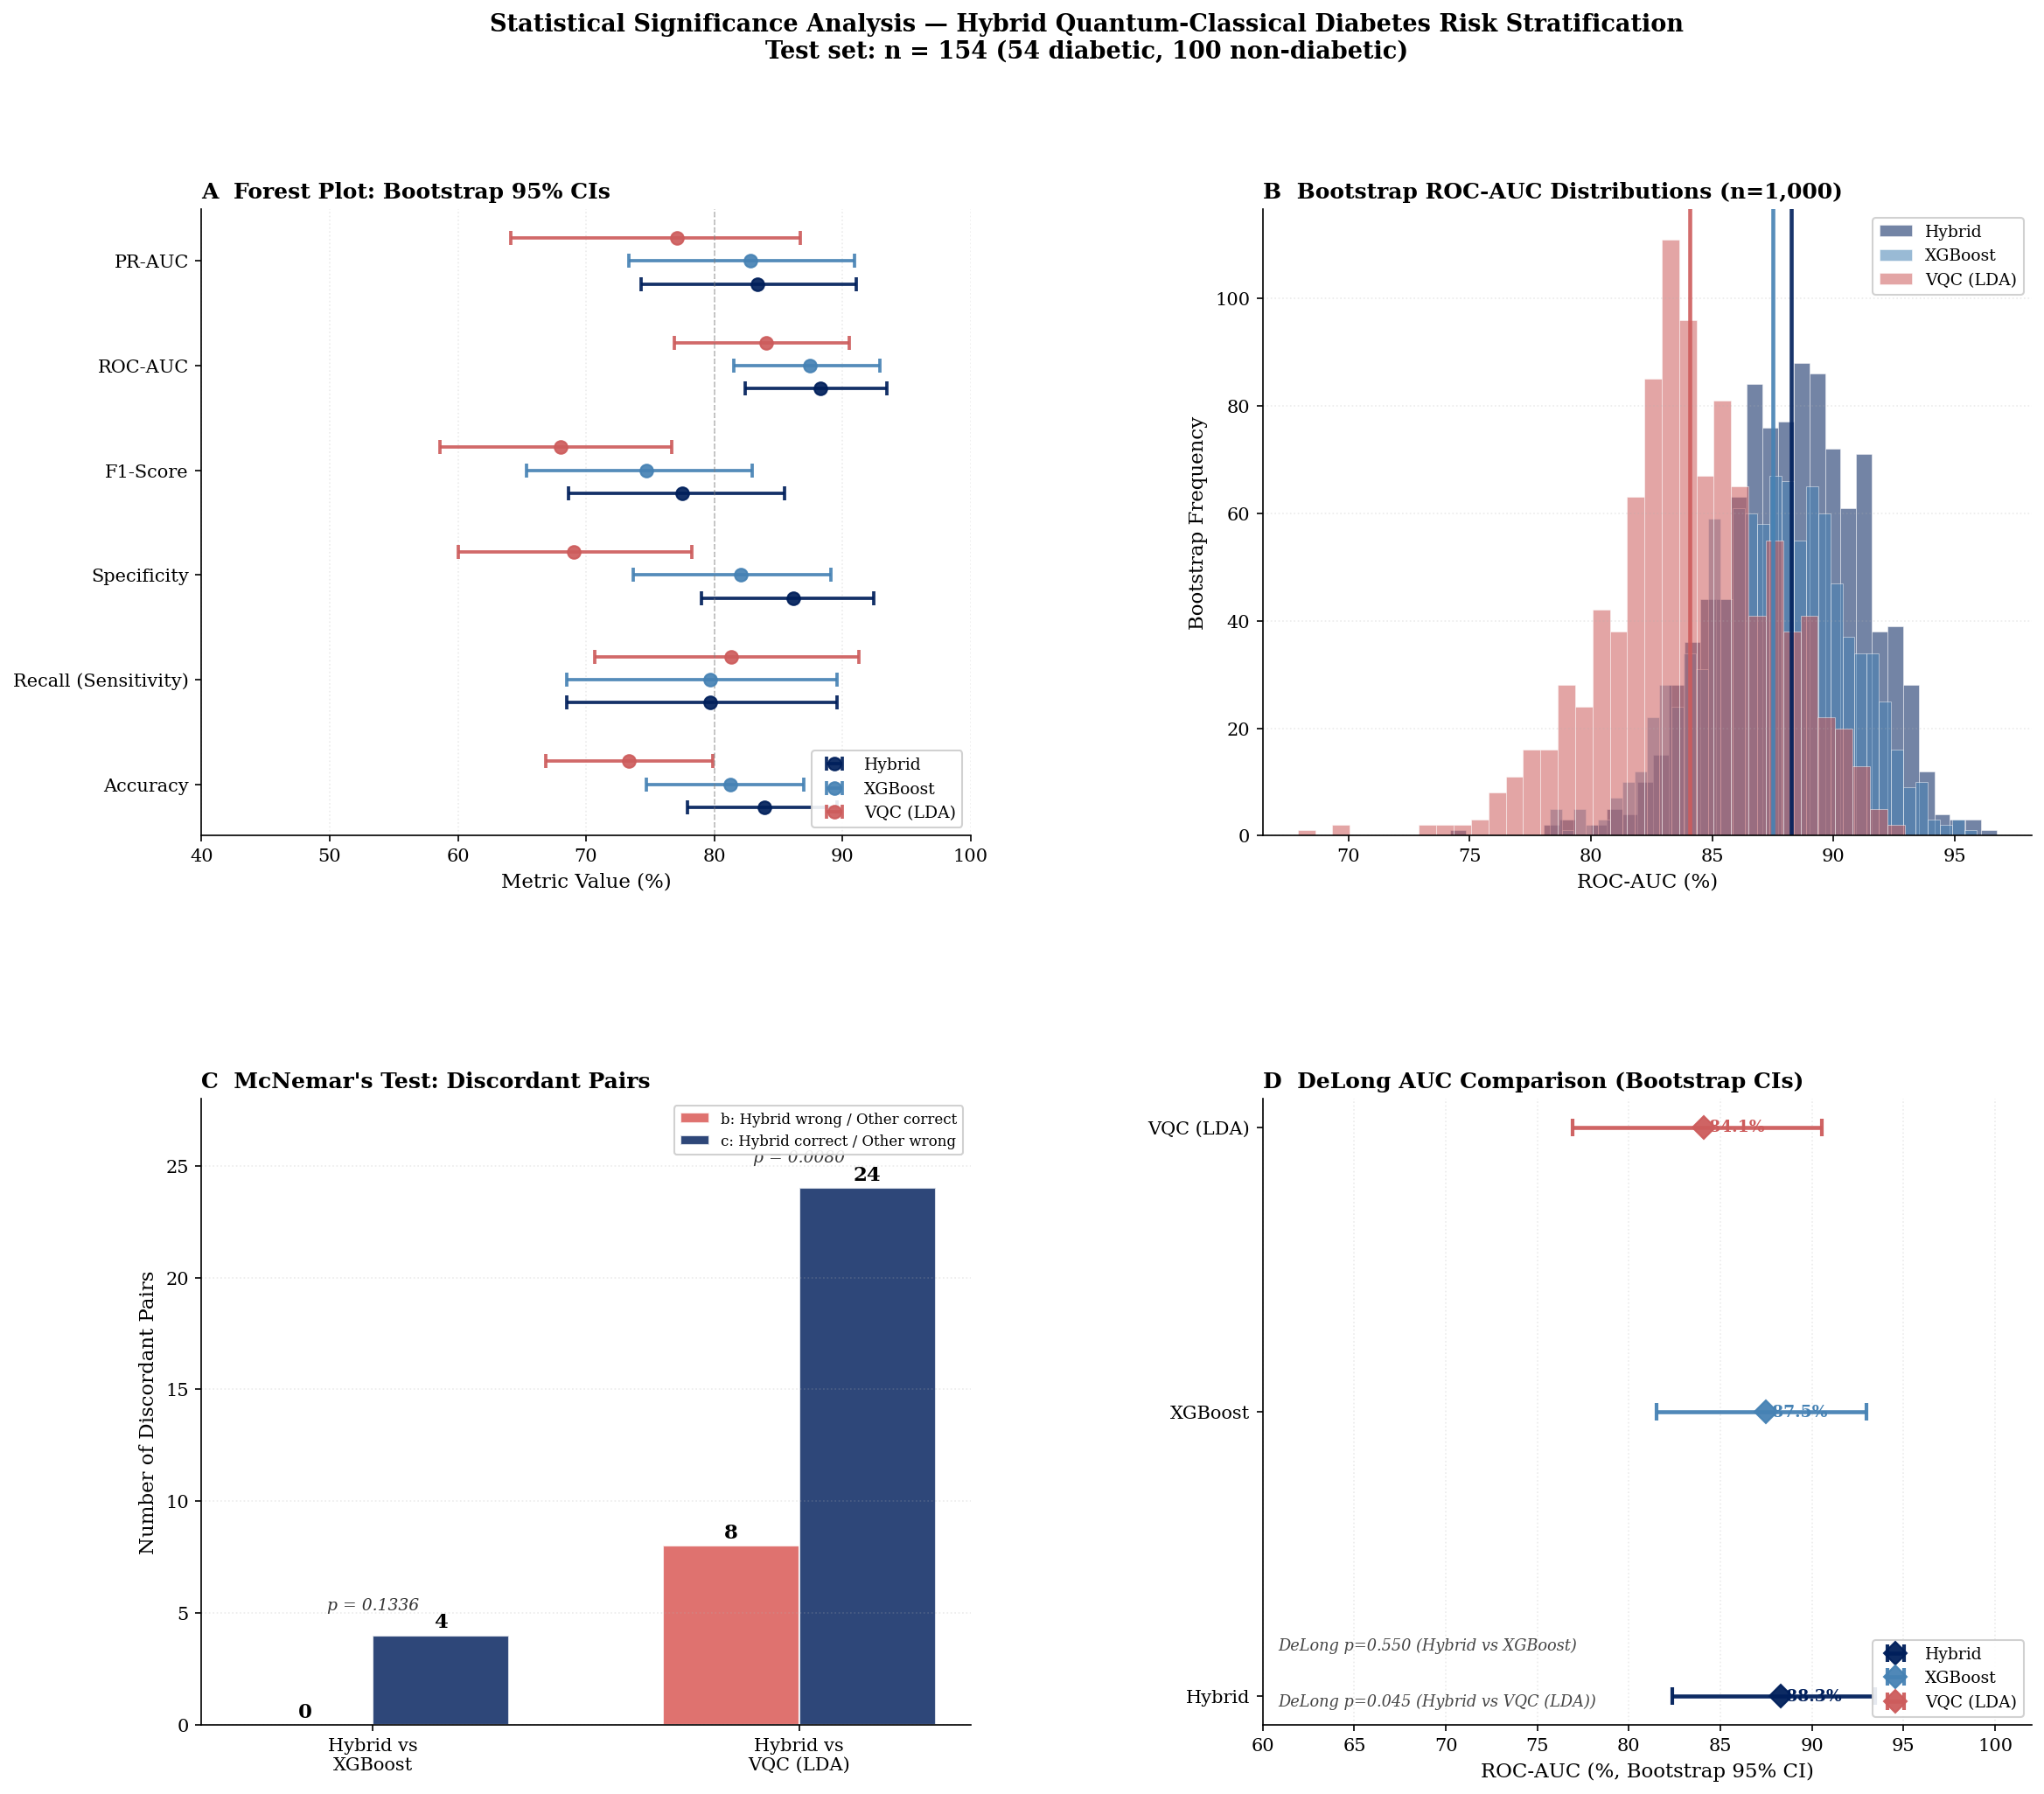

Saved: statistical_significance_analysis.pdf / .png


In [6]:
fig = plt.figure(figsize=(18, 15))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.42, wspace=0.38)

ax_forest  = fig.add_subplot(gs[0, 0])
ax_bootauc = fig.add_subplot(gs[0, 1])
ax_mcnemar = fig.add_subplot(gs[1, 0])
ax_delong  = fig.add_subplot(gs[1, 1])



forest_metrics = ['Accuracy', 'Recall (Sensitivity)', 'Specificity', 'F1-Score', 'ROC-AUC', 'PR-AUC']
models_order   = ['Hybrid', 'XGBoost', 'VQC (LDA)']
model_colors   = [COLORS['Hybrid'], COLORS['XGBoost'], COLORS['VQC (LDA)']]
boot_all       = {'Hybrid': boot_hybrid, 'XGBoost': boot_xgb, 'VQC (LDA)': boot_vqc}

metric_key_map = {
    'Accuracy':              'accuracy',
    'Recall (Sensitivity)':  'recall',
    'Specificity':           'specificity',
    'F1-Score':              'f1',
    'ROC-AUC':               'roc_auc',
    'PR-AUC':                'pr_auc',
}

y_positions = np.arange(len(forest_metrics))
offsets     = np.linspace(-0.22, 0.22, len(models_order))

for i, (model, color, offset) in enumerate(zip(models_order, model_colors, offsets)):
    boot_data = boot_all[model]
    means, lo, hi = [], [], []
    for mname in forest_metrics:
        key  = metric_key_map[mname]
        vals = boot_data[key]
        means.append(vals['mean'])
        lo.append(vals['mean'] - vals['ci_lower'])
        hi.append(vals['ci_upper'] - vals['mean'])

    ypos = y_positions + offset
    ax_forest.errorbar(
        means, ypos,
        xerr=[lo, hi],
        fmt='o', color=color,
        markersize=7, linewidth=1.8,
        capsize=4, capthick=1.8,
        label=model, alpha=0.92
    )

ax_forest.set_yticks(y_positions)
ax_forest.set_yticklabels(forest_metrics, fontsize=10)
ax_forest.set_xlabel('Metric Value (%)', fontsize=11)
ax_forest.set_title('A  Forest Plot: Bootstrap 95% CIs', fontsize=12, fontweight='bold', loc='left')
ax_forest.legend(loc='lower right', framealpha=0.9, fontsize=9)
ax_forest.axvline(x=80, color='grey', linestyle='--', linewidth=0.8, alpha=0.5)
ax_forest.set_xlim(40, 100)
ax_forest.grid(axis='x', alpha=0.25, linestyle=':')



for model, color in zip(models_order, model_colors):
    auc_vals = np.array(boot_all[model]['roc_auc']['mean'] * np.ones(N_BOOTSTRAP))  # fallback
    # Use raw bootstrap distributions
    if model == 'Hybrid':
        raw_aucs = np.array(boot_h_raw['roc_auc'])
    elif model == 'XGBoost':
        raw_aucs = np.array(boot_x_raw['roc_auc'])
    else:
        raw_aucs = np.array(boot_v_raw['roc_auc'])

    ax_bootauc.hist(
        raw_aucs, bins=35, alpha=0.55,
        color=color, label=model,
        edgecolor='white', linewidth=0.4
    )
    ax_bootauc.axvline(
        np.mean(raw_aucs), color=color,
        linestyle='-', linewidth=2.2, alpha=0.9
    )

ax_bootauc.set_xlabel('ROC-AUC (%)', fontsize=11)
ax_bootauc.set_ylabel('Bootstrap Frequency', fontsize=11)
ax_bootauc.set_title('B  Bootstrap ROC-AUC Distributions (n=1,000)', fontsize=12, fontweight='bold', loc='left')
ax_bootauc.legend(framealpha=0.9, fontsize=9)
ax_bootauc.grid(axis='y', alpha=0.25, linestyle=':')



comparisons = [f"Hybrid vs\n{r['label_b']}" for r in mcnemar_results]
b_vals      = [r['b_discordant'] for r in mcnemar_results]
c_vals      = [r['c_discordant'] for r in mcnemar_results]
x_pos       = np.arange(len(comparisons))
bar_w       = 0.32

bars_b = ax_mcnemar.bar(x_pos - bar_w/2, b_vals, bar_w,
                        label='b: Hybrid wrong / Other correct',
                        color='#d9534f', alpha=0.82, edgecolor='white')
bars_c = ax_mcnemar.bar(x_pos + bar_w/2, c_vals, bar_w,
                        label='c: Hybrid correct / Other wrong',
                        color=COLORS['Hybrid'], alpha=0.82, edgecolor='white')

for bar in bars_b:
    h = bar.get_height()
    ax_mcnemar.text(bar.get_x() + bar.get_width()/2, h + 0.15,
                    str(int(h)), ha='center', va='bottom', fontsize=11, fontweight='bold')
for bar in bars_c:
    h = bar.get_height()
    ax_mcnemar.text(bar.get_x() + bar.get_width()/2, h + 0.15,
                    str(int(h)), ha='center', va='bottom', fontsize=11, fontweight='bold')

# Annotate p-values
for i, r in enumerate(mcnemar_results):
    pstr = f"p = {r['p_value']:.4f}"
    ax_mcnemar.text(i, max(b_vals[i], c_vals[i]) + 1.0, pstr,
                    ha='center', va='bottom', fontsize=9,
                    color='#333333', style='italic')

ax_mcnemar.set_xticks(x_pos)
ax_mcnemar.set_xticklabels(comparisons, fontsize=10)
ax_mcnemar.set_ylabel('Number of Discordant Pairs', fontsize=11)
ax_mcnemar.set_title("C  McNemar's Test: Discordant Pairs", fontsize=12, fontweight='bold', loc='left')
ax_mcnemar.legend(loc='upper right', fontsize=8, framealpha=0.9)
ax_mcnemar.grid(axis='y', alpha=0.25, linestyle=':')
ax_mcnemar.set_ylim(0, max(max(b_vals), max(c_vals)) + 4)



dl_labels  = [f"Hybrid vs\n{r['label_b']}" for r in delong_results]
dl_auc_a   = [r['auc_a']       for r in delong_results]
dl_auc_b   = [r['auc_b']       for r in delong_results]
dl_ci_lo_a = [r['auc_a'] - r['ci_lower_95'] for r in delong_results]
dl_ci_hi_a = [r['ci_upper_95'] - r['auc_a'] for r in delong_results]


h_auc_mean = boot_hybrid['roc_auc']['mean']
h_auc_lo   = h_auc_mean - boot_hybrid['roc_auc']['ci_lower']
h_auc_hi   = boot_hybrid['roc_auc']['ci_upper'] - h_auc_mean
x_auc_mean = boot_xgb['roc_auc']['mean']
x_auc_lo   = x_auc_mean - boot_xgb['roc_auc']['ci_lower']
x_auc_hi   = boot_xgb['roc_auc']['ci_upper'] - x_auc_mean
v_auc_mean = boot_vqc['roc_auc']['mean']
v_auc_lo   = v_auc_mean - boot_vqc['roc_auc']['ci_lower']
v_auc_hi   = boot_vqc['roc_auc']['ci_upper'] - v_auc_mean

model_auc_data = [
    ('Hybrid',    h_auc_mean, h_auc_lo, h_auc_hi, COLORS['Hybrid']),
    ('XGBoost',   x_auc_mean, x_auc_lo, x_auc_hi, COLORS['XGBoost']),
    ('VQC (LDA)', v_auc_mean, v_auc_lo, v_auc_hi, COLORS['VQC (LDA)']),
]

y_dl = np.arange(len(model_auc_data))
for i, (name, mean_v, lo, hi, col) in enumerate(model_auc_data):
    ax_delong.errorbar(
        mean_v, y_dl[i],
        xerr=[[lo], [hi]],
        fmt='D', color=col,
        markersize=9, linewidth=2.2,
        capsize=5, capthick=2,
        label=name, alpha=0.95
    )
    ax_delong.text(mean_v + 0.3, y_dl[i], f'{mean_v:.1f}%',
                   va='center', ha='left', fontsize=9, color=col, fontweight='bold')


for j, r in enumerate(delong_results):
    pstr = f"DeLong p={r['p_value']:.3f} (Hybrid vs {r['label_b']})"
    ax_delong.text(
        0.02, 0.12 - j * 0.09, pstr,
        transform=ax_delong.transAxes,
        fontsize=8.5, color='#444444', style='italic'
    )

ax_delong.set_yticks(y_dl)
ax_delong.set_yticklabels([d[0] for d in model_auc_data], fontsize=10)
ax_delong.set_xlabel('ROC-AUC (%, Bootstrap 95% CI)', fontsize=11)
ax_delong.set_title('D  DeLong AUC Comparison (Bootstrap CIs)', fontsize=12, fontweight='bold', loc='left')
ax_delong.legend(loc='lower right', fontsize=9, framealpha=0.9)
ax_delong.grid(axis='x', alpha=0.25, linestyle=':')
ax_delong.set_xlim(60, 102)

fig.suptitle(
    'Statistical Significance Analysis — Hybrid Quantum-Classical Diabetes Risk Stratification\n'
    'Test set: n = 154 (54 diabetic, 100 non-diabetic)',
    fontsize=13, fontweight='bold', y=0.98
)

plt.savefig(FIG_DIR / 'statistical_significance_analysis.pdf',
            bbox_inches='tight', dpi=300)
plt.savefig(FIG_DIR / 'statistical_significance_analysis.png',
            bbox_inches='tight', dpi=200)
plt.show()
print('Saved: statistical_significance_analysis.pdf / .png')

In [7]:

def interpret_mcnemar(r):
    if r['significant_at_0.05']:
        return f'Significant — Hybrid significantly better (p={r["p_value"]})'
    elif r['significant_at_0.10']:
        return f'Marginally significant at alpha=0.10 (p={r["p_value"]})'
    else:
        return f'Not significant (p={r["p_value"]}) — insufficient power at n=154'

def interpret_delong(r):
    if r['significant_at_0.05']:
        return (f'Significant AUC improvement: {r["diff_pct"]:+.2f}%, '
                f'95%CI [{r["ci_lower_95"]}, {r["ci_upper_95"]}]%')
    else:
        return (f'Not significant: AUC diff={r["diff_pct"]:+.2f}%, '
                f'95%CI [{r["ci_lower_95"]}, {r["ci_upper_95"]}]% — includes 0')


sig_summary = pd.DataFrame([
    {
        'Test':                "McNemar's (Hybrid vs XGBoost)",
        'Statistic':           f"chi2={mcnemar_results[0]['chi2_stat']}",
        'p-value':             mcnemar_results[0]['p_value'],
        'Significant (0.05)':  mcnemar_results[0]['significant_at_0.05'],
        'Interpretation':      interpret_mcnemar(mcnemar_results[0]),
    },
    {
        'Test':                "McNemar's (Hybrid vs VQC)",
        'Statistic':           f"chi2={mcnemar_results[1]['chi2_stat']}",
        'p-value':             mcnemar_results[1]['p_value'],
        'Significant (0.05)':  mcnemar_results[1]['significant_at_0.05'],
        'Interpretation':      interpret_mcnemar(mcnemar_results[1]),
    },
    {
        'Test':                'DeLong (Hybrid vs XGBoost AUC)',
        'Statistic':           f"Z={delong_results[0]['z_stat']}",
        'p-value':             delong_results[0]['p_value'],
        'Significant (0.05)':  delong_results[0]['significant_at_0.05'],
        'Interpretation':      interpret_delong(delong_results[0]),
    },
    {
        'Test':                'DeLong (Hybrid vs VQC AUC)',
        'Statistic':           f"Z={delong_results[1]['z_stat']}",
        'p-value':             delong_results[1]['p_value'],
        'Significant (0.05)':  delong_results[1]['significant_at_0.05'],
        'Interpretation':      interpret_delong(delong_results[1]),
    },
])

print('Significance Summary Table:')
print('=' * 100)
print(sig_summary.to_string(index=False))
print('=' * 100)

sig_summary.to_csv(TAB_DIR / 'significance_summary.csv', index=False)
print('\nSaved: significance_summary.csv')


print('\nObserved Point Estimates (from known results):')
observed = pd.DataFrame([
    {'Model': 'Hybrid (τ=0.45)',   'Acc%': 83.77, 'Prec%': 75.44,
     'Recall%': 79.63, 'Spec%': 86.00, 'F1%': 77.48,
     'MCC': 0.6486, 'ROC-AUC%': 88.13, 'PR-AUC%': 83.04},
    {'Model': 'XGBoost (τ=0.50)', 'Acc%': 81.17, 'Prec%': None,
     'Recall%': 79.63, 'Spec%': None, 'F1%': 74.78,
     'MCC': 0.6013, 'ROC-AUC%': 87.33, 'PR-AUC%': None},
    {'Model': 'VQC-LDA (τ=0.50)', 'Acc%': 73.38, 'Prec%': None,
     'Recall%': 81.48, 'Spec%': None, 'F1%': 68.22,
     'MCC': 0.4819, 'ROC-AUC%': 84.07, 'PR-AUC%': None},
    {'Model': 'QSVC-LDA (τ=0.50)','Acc%': 77.27, 'Prec%': None,
     'Recall%': 77.78, 'Spec%': None, 'F1%': 70.59,
     'MCC': 0.5292, 'ROC-AUC%': 84.59, 'PR-AUC%': None},
])
print(observed.to_string(index=False))
observed.to_csv(TAB_DIR / 'observed_performance_summary.csv', index=False)
print('\nSaved: observed_performance_summary.csv')

Significance Summary Table:
                          Test   Statistic  p-value  Significant (0.05)                                                      Interpretation
 McNemar's (Hybrid vs XGBoost)   chi2=2.25   0.1336               False            Not significant (p=0.1336) — insufficient power at n=154
     McNemar's (Hybrid vs VQC) chi2=7.0312   0.0080                True                 Significant — Hybrid significantly better (p=0.008)
DeLong (Hybrid vs XGBoost AUC)    Z=0.5978   0.5500               False Not significant: AUC diff=+0.80%, 95%CI [-1.81, 3.41]% — includes 0
    DeLong (Hybrid vs VQC AUC)    Z=2.0055   0.0449                True            Significant AUC improvement: +4.06%, 95%CI [0.09, 8.02]%

Saved: significance_summary.csv

Observed Point Estimates (from known results):
            Model  Acc%  Prec%  Recall%  Spec%   F1%    MCC  ROC-AUC%  PR-AUC%
  Hybrid (τ=0.45) 83.77  75.44    79.63   86.0 77.48 0.6486     88.13    83.04
 XGBoost (τ=0.50) 81.17    NaN   